# NB01 - Praproses Dataset

Notebook ini menyiapkan citra buah untuk simulasi buta warna. Seleksi warna dilakukan otomatis pada tingkat kelas: piksel sampel dari gambar sekelas dipool, lalu Otsu dan K-means masing-masing di-fit sekali per kelas. Semua gambar pada kelas terpilih dipertahankan sebelum deduplikasi.

1. Setup dan konfigurasi
2. Inventarisasi dataset mentah
3. Pooling piksel dan klasifikasi warna otomatis per kelas
4. Pemilihan enam kelas teratas secara otomatis untuk tiap domain warna
5. Deduplikasi pHash per kelas
6. Center crop, resize, dan pembuatan manifest
7. Verifikasi hasil praproses
8. Undersampling seimbang per kelas dan per domain
9. Analisis ringkas dan ekspor


In [1]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [ ]:
from __future__ import annotations

import json
import random
import sys
import time
from pathlib import Path

import os
import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv, write_json

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
RANDOM_SEED = 42
METHOD_VERSION = "dataset-preparation-5.0-automatic-color-segmentation"

# Algorithm parameters: tune against a representative validation subset and
# report the final values. These are not coefficients from the cited equations.
COLOR_SAMPLES_PER_IMAGE = 1000
MAX_KMEANS_PIXELS_PER_CLASS = 20000
KMEANS_CLUSTERS = 4 # dari pham (2015)
MIN_CLASS_IMAGES = 30
CLASSES_PER_DOMAIN = 6
MIN_TARGET_COLOR_RATIO = 0.35 # hamza () persamaan 18-20
MIN_TARGET_MARGIN = 0.10
MAX_BROWN_CLASS_RATIO = 0.20
MAX_LOW_B_RED_RATIO = 0.20 # zhu (2022)
LOW_LIGHTNESS_LIMIT = 45.0 # zhu (2022)
LOW_BLUE_AXIS_LIMIT = 20.0 # zhu (2022)
HUE_RED_ORANGE_MAX = 45.0 # zhu (2022)
HUE_RED_WRAP_MIN = 345.0 # zhu (2022)
HUE_GREEN_MIN = 46.0 # zhu (2022)
HUE_GREEN_MAX = 160.0 # zhu (2022)
BROWN_HUE_MIN = 15.0
BROWN_HUE_MAX = 50.0
BROWN_VALUE_MAX = 0.65
OTSU_MIN_SATURATION = 0.08
CENTER_PRIOR_FRACTION = 0.50

ALL_RAW_CLASSES = sorted(
    directory.name for directory in RAW_DATASET_DIR.iterdir()
    if directory.is_dir() and directory.name != "000neg" and (directory / SUBSET).exists()
)


## Tahap 2 - Inventarisasi Seluruh Kelas Mentah

In [3]:
def list_images(directory: Path) -> list[Path]:
    return sorted(path for path in directory.rglob("*") if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS)

inventory_rows = []
for source_class in ALL_RAW_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    paths = list_images(class_dir) if class_dir.exists() else []
    inventory_rows.append({"source_class": source_class, "subset": SUBSET, "raw_image_count": len(paths), "source_directory": str(class_dir)})

inventory = pd.DataFrame(inventory_rows)
if (inventory["raw_image_count"] == 0).any():
    missing = inventory.loc[inventory["raw_image_count"] == 0, "source_class"].tolist()
    raise RuntimeError(f"Kelas tanpa citra pada subset train: {missing}")

print(inventory.to_string(index=False))
print(f"Total kelas mentah: {len(inventory)}")
print(f"Total citra raw: {int(inventory['raw_image_count'].sum())}")


  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\colorblind_simulation\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\colorblind_simulation\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\colorblind_simulation\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\colorblind_simulation\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\colorblind_simulation\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\colorblind_simulation\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\colorblind_simulation\research\datasets\raw\fruits\007watermelon\train
       008kiwi  train              311        C:\colorblind_simulation\research\datasets

## Tahap 3 - Seleksi Warna pada Tingkat Kelas

Seleksi dilakukan **per kelas**, bukan per gambar. Semua gambar dalam satu kelas menyumbang jumlah piksel sampel yang sama ke dalam kumpulan data kelas. Otsu dan K-means masing-masing dijalankan sekali pada kumpulan tersebut. Hasil klasifikasi warna satu kelas menentukan apakah seluruh kelas masuk domain Red-Orange, Green-Yellow, atau dikeluarkan sebagai kelas ambigu/cokelat. Tidak ada keputusan lolos atau tolak yang dibuat untuk gambar individual.

Untuk setiap kelas, ambang Otsu dihitung dari histogram saturasi gabungan. Kriteria varians antarkelas yang dipakai:

\[
t^* = \arg\max_t \sigma_B^2(t), \qquad
\sigma_B^2(t)=\omega_0(t)\omega_1(t)[\mu_0(t)-\mu_1(t)]^2
\]

Bentuk varians antarkelas ini mengikuti Otsu (1979), [A Threshold Selection Method from Gray-Level Histograms](https://doi.org/10.1109/TSMC.1979.4310076). Studi pada citra tomat menggunakan pemisahan HSV dan binarisasi untuk memisahkan buah dari latar serta melaporkan bahwa ambang perlu disesuaikan untuk tipe warna buah: [Song et al., Frontiers in Plant Science, 2022](https://doi.org/10.3389/fpls.2022.859290).

Piksel sampel di atas ambang saturasi lalu dikelompokkan satu kali per kelas dengan K-means dalam CIELAB. Aturan assignment piksel ke centroid dan pembaruan centroid mengikuti persamaan pada studi segmentasi citra buah Pham dan Lee (2015):

\[
\mathbf{x} \in C_i \quad\text{jika}\quad \operatorname{dist}(\mathbf{x},\mathbf{Z}_i) \leq \operatorname{dist}(\mathbf{x},\mathbf{Z}_j), \quad j=1,\ldots,K,\ i\ne j
\]

\[
\mathbf{Z}_k = \frac{1}{|C_k|}\sum_{s\in C_k}\mathbf{X}_s, \quad k=1,\ldots,K.
\]

Lihat [Pham dan Lee, An image segmentation approach for fruit defect detection using k-means clustering and graph-based algorithm, Vietnam Journal of Computer Science, 2, 25-33](https://doi.org/10.1007/s40595-014-0028-3). Nilai K, batas hue, rasio kemurnian, dan jumlah sampel per gambar adalah parameter operasional yang dicatat di konfigurasi, bukan persamaan yang diklaim berasal dari artikel.

Proporsi piksel warna dipakai untuk menentukan domain kelas. Notasi `Area` mengikuti bentuk fitur luas warna pada Hamza dan Chtourou (2020), Bagian 4.2, Persamaan 18-20, yang menghitung jumlah piksel warna relatif terhadap jumlah piksel buah:

\[
\mathrm{Area}_{RO,c}=\frac{n_{RO,c}}{n_c}, \qquad
\mathrm{Area}_{GY,c}=\frac{n_{GY,c}}{n_c}.
\]

Di sini, $n_{RO,c}$ dan $n_{GY,c}$ adalah jumlah piksel sampel kelas $c$ yang masuk cluster Red-Orange dan Green-Yellow; $n_c$ adalah jumlah piksel kelas $c$ yang benar-benar dipakai pada fit K-means setelah Otsu dan pembatasan jumlah sampel. Nilainya berupa proporsi 0-1; kalikan 100 jika ingin dinyatakan sebagai persentase. Fungsi persamaannya sama dengan fitur area warna pada artikel, tetapi penyebut NB01 bukan mask luas buah tersegmentasi. Karena itu, sitasi mendukung bentuk fitur proporsi warna, bukan menyatakan bahwa NB01 melakukan segmentasi objek buah seperti artikel tersebut. Nilai minimum proporsi dan margin klasifikasi tetap parameter operasional penelitian.

Rujukan: [Hamza dan Chtourou, *Design of fuzzy inference system for apple ripeness estimation using gradient method*, IET Image Processing, Section 4.2, Eqs. 18-20](https://doi.org/10.1049/iet-ipr.2018.6524).

**Batas metode:** pooling kelas mengurangi keputusan yang dipengaruhi satu citra, tetapi tidak mengenali objek buah secara semantik. Sampel diambil dari area tengah dengan asumsi dataset menempatkan buah di sekitar tengah. Karena itu rasio warna kelas dan jumlah piksel sampel disimpan di laporan audit untuk penilaian metodologis.

In [4]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    )


def collect_class_color_samples(image_paths: list[Path]) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Pool an equal number of center-region pixels from every image in one class."""
    hue_batches: list[np.ndarray] = []
    saturation_batches: list[np.ndarray] = []
    value_batches: list[np.ndarray] = []
    lab_batches: list[np.ndarray] = []
    rng = np.random.default_rng(RANDOM_SEED)

    for image_path in image_paths:
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            continue
        height, width = image_bgr.shape[:2]
        roi_h = max(1, int(height * CENTER_PRIOR_FRACTION))
        roi_w = max(1, int(width * CENTER_PRIOR_FRACTION))
        top = (height - roi_h) // 2
        left = (width - roi_w) // 2
        roi = image_bgr[top:top + roi_h, left:left + roi_w]
        pixels = roi.reshape(-1, 3)
        if pixels.size == 0:
            continue
        sample_size = min(COLOR_SAMPLES_PER_IMAGE, len(pixels))
        sample_indices = rng.choice(len(pixels), size=sample_size, replace=False)
        sampled_bgr = pixels[sample_indices].reshape(-1, 1, 3)

        sampled_hsv = cv2.cvtColor(sampled_bgr, cv2.COLOR_BGR2HSV).reshape(-1, 3)
        sampled_lab = cv2.cvtColor(
            sampled_bgr.astype(np.float32) / 255.0,
            cv2.COLOR_BGR2LAB,
        ).reshape(-1, 3)
        hue_batches.append(sampled_hsv[:, 0].astype(np.float32) * 2.0)
        saturation_batches.append(sampled_hsv[:, 1].astype(np.float32) / 255.0)
        value_batches.append(sampled_hsv[:, 2].astype(np.float32) / 255.0)
        lab_batches.append(sampled_lab.astype(np.float32))

    if not hue_batches:
        empty = np.array([], dtype=np.float32)
        return empty, empty, empty, np.empty((0, 3), dtype=np.float32)
    return (
        np.concatenate(hue_batches),
        np.concatenate(saturation_batches),
        np.concatenate(value_batches),
        np.vstack(lab_batches),
    )


def evaluate_class_color(class_name: str, image_paths: list[Path]) -> dict:
    """Fit Otsu and K-means once on the pooled pixel sample for one fruit class."""
    hue, saturation, value, lab = collect_class_color_samples(image_paths)
    result = {
        "source_class": class_name,
        "image_count": len(image_paths),
        "sampled_pixel_count": int(saturation.size),
        "otsu_saturation_threshold": np.nan,
        "red_orange_ratio": 0.0,
        "green_yellow_ratio": 0.0,
        "brown_ratio": 0.0,
        "low_b_red_ratio": 0.0,
        "target_color_ratio": 0.0,
        "color_margin": 0.0,
        "domain": "Ambiguous/Brown",
        "status": "Rejected",
        "rejection_reason": "no_usable_pixels",
    }
    if saturation.size < KMEANS_CLUSTERS * 10:
        return result

    saturation_u8 = np.clip(saturation * 255.0, 0, 255).astype(np.uint8)
    otsu_threshold, _ = cv2.threshold(
        saturation_u8.reshape(-1, 1),
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU,
    )
    threshold = max(float(otsu_threshold), OTSU_MIN_SATURATION * 255.0)
    chromatic_indices = np.flatnonzero(saturation_u8 >= threshold)
    result["otsu_saturation_threshold"] = threshold / 255.0
    if chromatic_indices.size < KMEANS_CLUSTERS * 10:
        result["rejection_reason"] = "insufficient_chromatic_class_samples"
        return result

    fit_count = min(MAX_KMEANS_PIXELS_PER_CLASS, chromatic_indices.size)
    rng = np.random.default_rng(RANDOM_SEED)
    fit_indices = rng.choice(chromatic_indices, size=fit_count, replace=False)
    fit_lab = lab[fit_indices].astype(np.float32)
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        50,
        0.2,
    )
    cv2.setRNGSeed(RANDOM_SEED)
    _, labels, centers = cv2.kmeans(
        fit_lab,
        KMEANS_CLUSTERS,
        None,
        criteria,
        3,
        cv2.KMEANS_PP_CENTERS,
    )

    selected_hue = hue[fit_indices]
    selected_value = value[fit_indices]
    cluster_labels = labels.reshape(-1)
    cluster_counts = np.bincount(cluster_labels, minlength=KMEANS_CLUSTERS)
    cluster_is_red = np.zeros(KMEANS_CLUSTERS, dtype=bool)
    cluster_is_green = np.zeros(KMEANS_CLUSTERS, dtype=bool)
    cluster_is_brown = np.zeros(KMEANS_CLUSTERS, dtype=bool)
    cluster_is_low_b_red = np.zeros(KMEANS_CLUSTERS, dtype=bool)
    for cluster_id in range(KMEANS_CLUSTERS):
        members = cluster_labels == cluster_id
        if not members.any():
            continue
        angles = np.deg2rad(selected_hue[members])
        mean_hue = float(np.rad2deg(np.arctan2(np.sin(angles).mean(), np.cos(angles).mean())) % 360.0)
        mean_value = float(selected_value[members].mean())
        cluster_is_brown[cluster_id] = (
            BROWN_HUE_MIN <= mean_hue <= BROWN_HUE_MAX
            and mean_value < BROWN_VALUE_MAX
        )
        cluster_is_red[cluster_id] = (
            (mean_hue <= HUE_RED_ORANGE_MAX or mean_hue >= HUE_RED_WRAP_MIN)
            and not cluster_is_brown[cluster_id]
        )
        cluster_is_green[cluster_id] = (HUE_GREEN_MIN <= mean_hue <= HUE_GREEN_MAX) and not cluster_is_brown[cluster_id]
        cluster_is_low_b_red[cluster_id] = (
            cluster_is_red[cluster_id]
            and centers[cluster_id, 0] < LOW_LIGHTNESS_LIMIT
            and centers[cluster_id, 2] < LOW_BLUE_AXIS_LIMIT
        )

    total = float(cluster_counts.sum())
    red_ratio = float(cluster_counts[cluster_is_red].sum() / total)
    green_ratio = float(cluster_counts[cluster_is_green].sum() / total)
    brown_ratio = float(cluster_counts[cluster_is_brown].sum() / total)
    low_b_red_ratio = float(cluster_counts[cluster_is_low_b_red].sum() / total)
    margin = abs(red_ratio - green_ratio)
    result.update({
        "red_orange_ratio": red_ratio,
        "green_yellow_ratio": green_ratio,
        "brown_ratio": brown_ratio,
        "low_b_red_ratio": low_b_red_ratio,
        "target_color_ratio": max(red_ratio, green_ratio),
        "color_margin": margin,
    })

    if brown_ratio > MAX_BROWN_CLASS_RATIO:
        result["rejection_reason"] = "brown_color_fraction_above_limit"
    elif low_b_red_ratio > MAX_LOW_B_RED_RATIO:
        result["rejection_reason"] = "dark_low_b_red_fraction_above_limit"
    elif brown_ratio >= MIN_TARGET_COLOR_RATIO and brown_ratio > max(red_ratio, green_ratio):
        result["rejection_reason"] = "brown_dominant_class"
    elif red_ratio >= MIN_TARGET_COLOR_RATIO and red_ratio - green_ratio >= MIN_TARGET_MARGIN:
        result.update({"domain": "Red-Orange", "status": "Eligible", "rejection_reason": ""})
    elif green_ratio >= MIN_TARGET_COLOR_RATIO and green_ratio - red_ratio >= MIN_TARGET_MARGIN:
        result.update({"domain": "Green-Yellow", "status": "Eligible", "rejection_reason": ""})
    else:
        result["rejection_reason"] = "mixed_or_low_class_color_ratio"
    return result


print("Menghitung Otsu dan K-means satu kali untuk setiap kelas...")
class_color_records = []
class_image_paths: dict[str, list[Path]] = {}
for class_name in ALL_RAW_CLASSES:
    paths = list_images(RAW_DATASET_DIR / class_name / SUBSET)
    class_image_paths[class_name] = paths
    class_color_records.append(evaluate_class_color(class_name, paths))

hue_audit = pd.DataFrame(class_color_records)
red_pool = hue_audit[hue_audit["domain"] == "Red-Orange"].sort_values(
    ["image_count", "target_color_ratio", "color_margin", "source_class"],
    ascending=[False, False, False, True],
)
green_pool = hue_audit[hue_audit["domain"] == "Green-Yellow"].sort_values(
    ["image_count", "target_color_ratio", "color_margin", "source_class"],
    ascending=[False, False, False, True],
)
if len(red_pool) < CLASSES_PER_DOMAIN or len(green_pool) < CLASSES_PER_DOMAIN:
    raise RuntimeError(
        "Hasil klasifikasi otomatis belum menyediakan cukup kelas per domain: "
        f"red-orange={len(red_pool)}, green-yellow={len(green_pool)}, "
        f"syarat={CLASSES_PER_DOMAIN}. Sesuaikan parameter berdasarkan audit kelas."
    )

red_selected = red_pool.head(CLASSES_PER_DOMAIN)["source_class"].tolist()
green_selected = green_pool.head(CLASSES_PER_DOMAIN)["source_class"].tolist()
SELECTED_CLASSES = tuple(sorted(red_selected + green_selected))
valid_domain_by_class = {
    **{name: "Red-Orange" for name in red_selected},
    **{name: "Green-Yellow" for name in green_selected},
}
hue_audit["status"] = hue_audit["source_class"].map(
    lambda name: "Selected" if name in SELECTED_CLASSES else (
        "EligibleNotSelected" if name in set(red_pool["source_class"]) | set(green_pool["source_class"]) else "Rejected"
    )
)
eliminated_classes = hue_audit.loc[hue_audit["status"] != "Selected", "source_class"].tolist()

# Every image in each selected class is retained; no instance-level color filtering is applied.
valid_images_by_class = {
    class_name: class_image_paths[class_name]
    for class_name in SELECTED_CLASSES
}

print("Kelas Red-Orange terpilih:", red_selected)
print("Kelas Green-Yellow terpilih:", green_selected)
print(hue_audit.sort_values(["domain", "image_count"], ascending=[True, False]).to_string(index=False))
print(f"Total citra pada kelas terpilih, sebelum deduplikasi: {sum(map(len, valid_images_by_class.values()))}")


Menghitung Otsu dan K-means satu kali untuk setiap kelas...
Kelas Red-Orange terpilih: ['005strawberry', '009peach', '002orange', '001apple', '004tomato', '010pomegranate']
Kelas Green-Yellow terpilih: ['006banana', '003pear', '007watermelon', '012starfruit', '014lemon', '015pomelo']
  source_class  image_count  sampled_pixel_count  otsu_saturation_threshold  red_orange_ratio  green_yellow_ratio  brown_ratio  low_b_red_ratio  target_color_ratio  color_margin          domain              status                    rejection_reason
       008kiwi          311               311000                   0.556863           0.22100             0.18525      0.59375           0.0000             0.22100       0.03575 Ambiguous/Brown            Rejected    brown_color_fraction_above_limit
  011pineapple          225               225000                   0.447059           0.58140             0.19820      0.22040           0.0000             0.58140       0.38320 Ambiguous/Brown            Rejected  

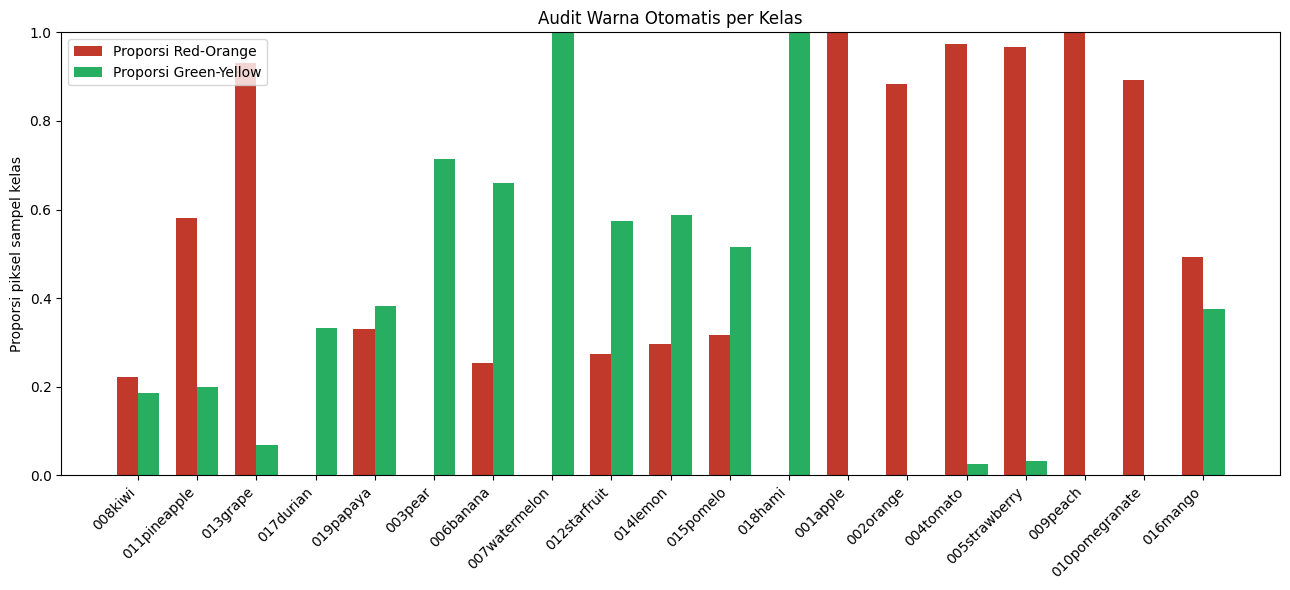

In [5]:
# Ringkasan audit pada tingkat kelas
fig, ax = plt.subplots(figsize=(13, 6))
audit_plot = hue_audit.sort_values(["domain", "source_class"])
x = np.arange(len(audit_plot))
width = 0.36
ax.bar(x - width / 2, audit_plot["red_orange_ratio"], width, label="Proporsi Red-Orange", color="#c0392b")
ax.bar(x + width / 2, audit_plot["green_yellow_ratio"], width, label="Proporsi Green-Yellow", color="#27ae60")
ax.set_xticks(x)
ax.set_xticklabels(audit_plot["source_class"], rotation=45, ha="right")
ax.set_ylabel("Proporsi piksel sampel kelas")
ax.set_ylim(0, 1)
ax.set_title("Audit Warna Otomatis per Kelas")
ax.legend()
plt.tight_layout()
plt.show()


### Analisis Tambahan Hasil Seleksi Kelas

Grafik berikut memperlihatkan komposisi warna hasil pooling sampel per kelas, pemisahan proporsi Red-Orange dan Green-Yellow, serta ambang saturasi Otsu per kelas. Grafik ini membantu memeriksa apakah kelas terpilih didukung oleh proporsi warna yang dominan dan seberapa besar variasi ambang antar kelas. Setiap titik dan batang tetap mewakili satu kelas, bukan satu gambar.

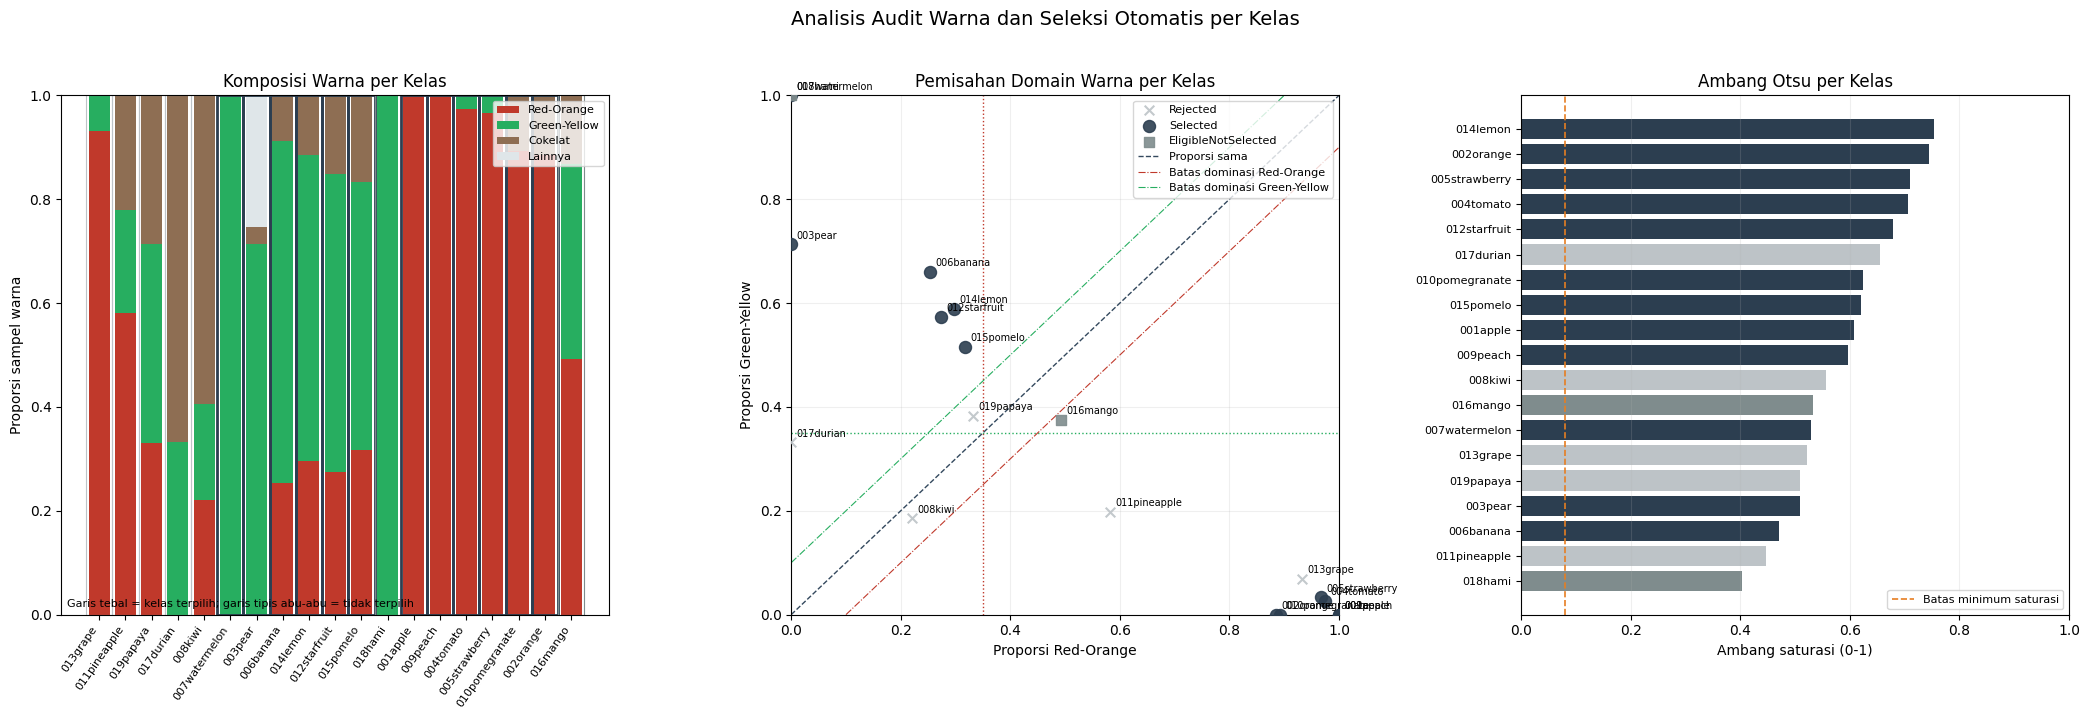

Grafik analisis seleksi kelas disimpan: C:\colorblind_simulation\research\notebooks\01\output\class_selection_analysis.png


In [6]:
# Analisis tambahan seleksi warna pada tingkat kelas
status_order = {"Selected": 0, "EligibleNotSelected": 1, "Rejected": 2}
status_colors = {
    "Selected": "#2c3e50",
    "EligibleNotSelected": "#7f8c8d",
    "Rejected": "#bdc3c7",
}
analysis_plot = hue_audit.copy()
analysis_plot["_status_order"] = analysis_plot["status"].map(status_order).fillna(3)
analysis_plot = analysis_plot.sort_values(
    ["domain", "_status_order", "target_color_ratio", "source_class"],
    ascending=[True, True, False, True],
).reset_index(drop=True)
analysis_plot["other_ratio"] = np.clip(
    1.0 - analysis_plot["red_orange_ratio"]
    - analysis_plot["green_yellow_ratio"]
    - analysis_plot["brown_ratio"],
    0.0,
    1.0,
)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
class_x = np.arange(len(analysis_plot))
bar_bottom = np.zeros(len(analysis_plot), dtype=float)
composition = [
    ("red_orange_ratio", "Red-Orange", "#c0392b"),
    ("green_yellow_ratio", "Green-Yellow", "#27ae60"),
    ("brown_ratio", "Cokelat", "#8e6e53"),
    ("other_ratio", "Lainnya", "#dfe6e9"),
]
for column, label, color in composition:
    values = analysis_plot[column].fillna(0).to_numpy(dtype=float)
    axes[0].bar(class_x, values, bottom=bar_bottom, label=label, color=color)
    bar_bottom += values
for index, row in analysis_plot.iterrows():
    axes[0].bar(
        index,
        1.0,
        width=1.0,
        fill=False,
        edgecolor=status_colors.get(row["status"], "black"),
        linewidth=2.0 if row["status"] == "Selected" else 0.8,
    )
axes[0].set_xticks(class_x)
axes[0].set_xticklabels(analysis_plot["source_class"], rotation=55, ha="right", fontsize=8)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Proporsi sampel warna")
axes[0].set_title("Komposisi Warna per Kelas")
axes[0].legend(fontsize=8, loc="upper right")
axes[0].text(
    0.01, 0.01,
    "Garis tebal = kelas terpilih; garis tipis abu-abu = tidak terpilih",
    transform=axes[0].transAxes, fontsize=8, va="bottom",
)

for status, group in analysis_plot.groupby("status", sort=False):
    axes[1].scatter(
        group["red_orange_ratio"],
        group["green_yellow_ratio"],
        label=status,
        color=status_colors.get(status, "black"),
        marker="o" if status == "Selected" else ("s" if status == "EligibleNotSelected" else "x"),
        s=75 if status == "Selected" else 48,
        alpha=0.9,
        zorder=3,
    )
for _, row in analysis_plot.iterrows():
    axes[1].annotate(
        row["source_class"],
        (row["red_orange_ratio"], row["green_yellow_ratio"]),
        xytext=(4, 4), textcoords="offset points", fontsize=7,
    )
limit = float(MIN_TARGET_COLOR_RATIO)
margin = float(MIN_TARGET_MARGIN)
axes[1].axvline(limit, color="#c0392b", linestyle=":", linewidth=1)
axes[1].axhline(limit, color="#27ae60", linestyle=":", linewidth=1)
axes[1].plot([0, 1], [0, 1], color="#34495e", linestyle="--", linewidth=1, label="Proporsi sama")
axes[1].plot([margin, 1], [0, 1 - margin], color="#c0392b", linestyle="-.", linewidth=0.8, label="Batas dominasi Red-Orange")
axes[1].plot([0, 1 - margin], [margin, 1], color="#27ae60", linestyle="-.", linewidth=0.8, label="Batas dominasi Green-Yellow")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Proporsi Red-Orange")
axes[1].set_ylabel("Proporsi Green-Yellow")
axes[1].set_title("Pemisahan Domain Warna per Kelas")
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8, loc="upper right")

otsu_plot = analysis_plot.dropna(subset=["otsu_saturation_threshold"]).copy()
otsu_plot = otsu_plot.sort_values("otsu_saturation_threshold")
otsu_y = np.arange(len(otsu_plot))
axes[2].barh(
    otsu_y,
    otsu_plot["otsu_saturation_threshold"],
    color=[status_colors.get(status, "black") for status in otsu_plot["status"]],
)
axes[2].set_yticks(otsu_y)
axes[2].set_yticklabels(otsu_plot["source_class"], fontsize=8)
axes[2].axvline(
    OTSU_MIN_SATURATION,
    color="#e67e22",
    linestyle="--",
    linewidth=1.2,
    label="Batas minimum saturasi",
)
axes[2].set_xlim(0, 1)
axes[2].set_xlabel("Ambang saturasi (0-1)")
axes[2].set_title("Ambang Otsu per Kelas")
axes[2].legend(fontsize=8, loc="lower right")
axes[2].grid(axis="x", alpha=0.2)

fig.suptitle("Analisis Audit Warna dan Seleksi Otomatis per Kelas", fontsize=14, y=1.02)
fig.tight_layout()
analysis_chart_path = OUTPUT_DIR / "class_selection_analysis.png"
fig.savefig(analysis_chart_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik analisis seleksi kelas disimpan: {analysis_chart_path}")


## Tahap 4 - Deduplikasi Perceptual Hash (pHash) Intra-Kelas

Deduplikasi dilakukan dalam kelas yang sama menggunakan *perceptual hash* berbasis Discrete Cosine Transform (DCT-II 2D $32 \times 32$) dan kuantisasi median koefisien frekuensi rendah $8 \times 8$ (*Mahmud, Nusrat, & Pan, 2026, Eq. 3-6; Zauner, 2010*).

Dua citra dalam kelas yang sama diklasifikasikan sebagai duplikat visual jika jarak Hamming antar-hash biner 64-bit tidak melebihi ambang batas 4 ($d_H \le 4$).

In [7]:
# -- Deduplikasi Perceptual Hash (pHash) Intra-Kelas --
# Referensi Ilmiah Terverifikasi:
#   Mahmud, M. F., Nusrat, Z., & Pan, W. D. (2026). Electronics, 15(7), 1493.
#   Equations (3)-(6): 2D DCT-II, Median 8x8 Quantization, and Hamming Distance.

def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as img:
        return imagehash.phash(img)


def deduplicate_images(
    image_paths: list[Path],
    threshold: int = PHASH_THRESHOLD,
) -> tuple[list[Path], list[tuple[Path, Path, int]]]:
    kept: list[Path] = []
    kept_hashes: list[imagehash.ImageHash] = []
    duplicates: list[tuple[Path, Path, int]] = []

    for path in image_paths:
        img_hash = compute_phash(path)
        is_duplicate = False
        for existing_hash, existing_path in zip(kept_hashes, kept):
            distance = img_hash - existing_hash
            if distance <= threshold:
                duplicates.append((path, existing_path, distance))
                is_duplicate = True
                break
        if not is_duplicate:
            kept.append(path)
            kept_hashes.append(img_hash)
    return kept, duplicates


dedup_results: dict[str, list[Path]] = {}
duplicate_records: list[dict] = []

# Hanya memproses citra yang lolos seleksi kemurnian kromatis dari 12 kelas terpilih
for cls_name in SELECTED_CLASSES:
    class_images = valid_images_by_class[cls_name]
    kept, dups = deduplicate_images(class_images, threshold=PHASH_THRESHOLD)
    dedup_results[cls_name] = kept
    for dup_path, orig_path, dist in dups:
        duplicate_records.append({
            "class": cls_name,
            "duplicate_file": dup_path.name,
            "kept_file": orig_path.name,
            "hamming_distance": dist,
        })

dedup_df = pd.DataFrame(duplicate_records)
print(f"Total kelas terpilih      : {len(SELECTED_CLASSES)}")
print(f"Total citra murni terpilih : {sum(len(v) for v in valid_images_by_class.values())}")
print(f"Total duplikat disaring   : {len(duplicate_records)}")
print(f"Total citra unik dipertahankan : {sum(len(v) for v in dedup_results.values())}")

# Bentuk daftar kandidat untuk praproses
candidates = [(cls_name, path) for cls_name in SELECTED_CLASSES for path in dedup_results[cls_name]]
print(f"Total kandidat unik siap praproses: {len(candidates)}")


Total kelas terpilih      : 12
Total citra murni terpilih : 3740
Total duplikat disaring   : 136
Total citra unik dipertahankan : 3604
Total kandidat unik siap praproses: 3604


## Tahap 5 - Normalisasi Geometris (Center Crop & Resize)

Citra dipotong secara simetris di bagian tengah (titik potong $(W - W_c)/2$ dan $(H - H_c)/2$) untuk menjaga rasio aspek objek 1:1 tanpa distorsi, kemudian di-resize ke resolusi seragam $512 \times 512$ piksel menggunakan interpolasi area (*Xiao et al., 2025, Eq. 4*).

In [8]:
# -- Normalisasi Geometris: Center-Crop Resizing 512x512 --
# Referensi Ilmiah Terverifikasi:
#   Xiao, Y. et al. (2025). J. Mar. Sci. Eng., 13(5), 936. (Equation 4: Center-Crop Transformation Matrix)

def center_crop_resize(source_path: Path, destination_path: Path, size: int) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")

manifest_rows: list[dict] = []
error_rows: list[dict] = []
for source_class, source_path in candidates:
    output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
    try:
        started = time.perf_counter()
        center_crop_resize(source_path, output_path, OUTPUT_SIZE)
        manifest_rows.append({"subset": SUBSET, "source_class": source_class, "source_file_name": source_path.name, "source_path": str(source_path), "output_file_name": output_path.name, "output_path": str(output_path), "output_sha256": sha256_file(output_path), "processing_seconds": round(time.perf_counter() - started, 6), "method_version": METHOD_VERSION})
    except Exception as error:
        error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

manifest = pd.DataFrame(manifest_rows).sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
manifest["color_domain"] = manifest["source_class"].map(valid_domain_by_class)
if manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil diproses.")
print(f"Citra berhasil diproses: {len(manifest)}")


Citra berhasil diproses: 3604


## Tahap 6 - Verifikasi Hasil Praproses

In [9]:
verification_rows = []
for _, row in manifest.iterrows():
    image = cv2.imread(row["output_path"], cv2.IMREAD_COLOR)
    verification_rows.append({"source_class": row["source_class"], "output_path": row["output_path"], "readable": image is not None, "width": None if image is None else int(image.shape[1]), "height": None if image is None else int(image.shape[0])})
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not ((verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra berukuran {OUTPUT_SIZE} × {OUTPUT_SIZE} piksel.")

Seluruh 3604 citra berukuran 512 × 512 piksel.


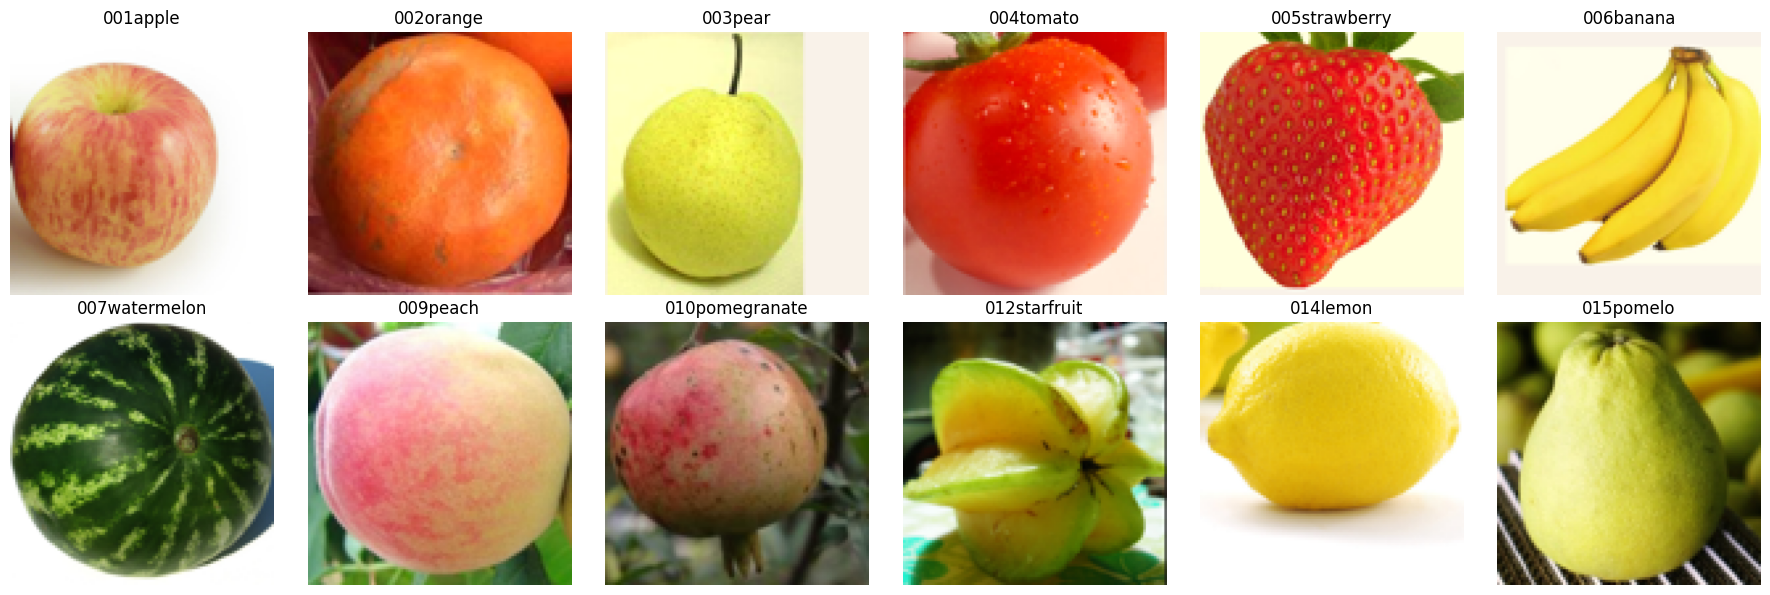

In [10]:
import math

# Mengambil 1 sampel acak untuk setiap kelas dari dataframe manifest
if "manifest" not in globals():
    raise RuntimeError(
        "Variabel `manifest` belum tersedia. Jalankan sel Tahap 4 terlebih dahulu."
    )

sample_df = (
    manifest.groupby("source_class")
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Hitung jumlah baris & kolom secara dinamis
num_samples = len(sample_df)
ncols = 6
nrows = math.ceil(num_samples / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3 * ncols, 3 * nrows))
axes = axes.flatten()

for idx, row in sample_df.iterrows():
    img = cv2.imread(row['output_path'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(row['source_class'], fontsize=12)
    axes[idx].axis('off')

# Matikan sisa subplot kosong jika total slot melebihi jumlah data
for j in range(num_samples, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Tahap 7 - Undersampling Seimbang per Kelas dan Domain

Setelah enam kelas otomatis terpilih pada setiap domain, kuota citra ditentukan dari kelas terpilih yang memiliki jumlah citra valid paling sedikit:

\[
n_{\text{kelas}} = \min_{c\in\mathcal{C}_{red}\cup\mathcal{C}_{green}} N_c
\]

Setiap kelas mengambil \(n_{\text{kelas}}\) citra dengan sampling acak ber-seed tetap. Dengan enam kelas pada setiap domain, jumlah kedua domain menjadi sama dan kontribusi kelas juga setara. Ini adalah aturan desain sampling penelitian, bukan persamaan yang diklaim sebagai rumus dari jurnal. Distribusi sebelum dan sesudah sampling diekspor agar keputusan dapat diaudit.


In [11]:
# Undersampling deterministik dengan kuota sama untuk setiap kelas terpilih
class_counts_before = manifest.groupby("source_class").size()
domain_counts_before = manifest.groupby("color_domain").size()
class_quota = int(class_counts_before.loc[list(SELECTED_CLASSES)].min())
if class_quota <= 0:
    raise RuntimeError("Kuota undersampling per kelas harus lebih dari nol.")

selected_chunks = []
for class_name in SELECTED_CLASSES:
    class_rows = manifest[manifest["source_class"] == class_name]
    selected_chunks.append(
        class_rows.sample(n=class_quota, random_state=RANDOM_SEED)
    )

manifest_balanced = (
    pd.concat(selected_chunks, ignore_index=True)
    .sort_values(["color_domain", "source_class", "source_file_name"])
    .reset_index(drop=True)
)
class_counts_after = manifest_balanced.groupby("source_class").size()
domain_counts_after = manifest_balanced.groupby("color_domain").size()
expected_domain_count = class_quota * CLASSES_PER_DOMAIN
if set(domain_counts_after.index) != {"Red-Orange", "Green-Yellow"}:
    raise RuntimeError(f"Domain hasil sampling tidak lengkap: {domain_counts_after.to_dict()}")
if not (domain_counts_after == expected_domain_count).all():
    raise RuntimeError(f"Jumlah domain tidak seimbang: {domain_counts_after.to_dict()}")
if not (class_counts_after == class_quota).all():
    raise RuntimeError("Kuota citra per kelas tidak konsisten.")

print(f"Kuota per kelas: {class_quota}")
print("Distribusi kelas setelah undersampling:")
print(class_counts_after.to_string())
print("Distribusi domain setelah undersampling:")
print(domain_counts_after.to_string())
print(f"Total citra setelah undersampling: {len(manifest_balanced)}")

manifest_original = manifest.copy()
manifest = manifest_balanced


Kuota per kelas: 112
Distribusi kelas setelah undersampling:
source_class
001apple          112
002orange         112
003pear           112
004tomato         112
005strawberry     112
006banana         112
007watermelon     112
009peach          112
010pomegranate    112
012starfruit      112
014lemon          112
015pomelo         112
Distribusi domain setelah undersampling:
color_domain
Green-Yellow    672
Red-Orange      672
Total citra setelah undersampling: 1344


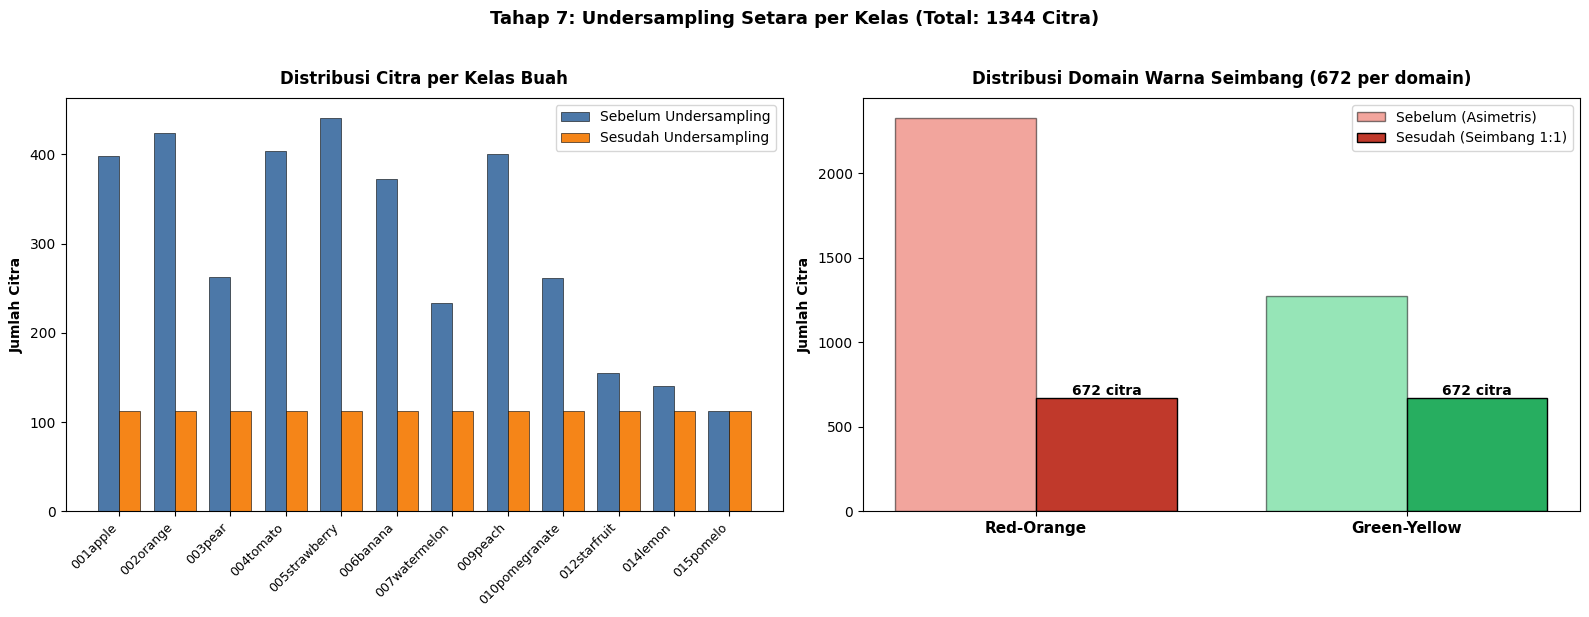

Laporan undersampling disimpan: C:\colorblind_simulation\research\notebooks\01\output\undersampling_report.csv


In [12]:
# -- Visualisasi Perbandingan Sebelum vs Sesudah Undersampling Domain --
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel kiri: per-kelas buah
cls_names = sorted(list(SELECTED_CLASSES))
before_vals = [int(class_counts_before.get(c, 0)) for c in cls_names]
after_vals = [int(class_counts_after.get(c, 0)) for c in cls_names]
x = np.arange(len(cls_names))
width = 0.38

axes[0].bar(x - width/2, before_vals, width, label="Sebelum Undersampling", color="#4C78A8", edgecolor="black", linewidth=0.4)
axes[0].bar(x + width/2, after_vals, width, label="Sesudah Undersampling", color="#F58518", edgecolor="black", linewidth=0.4)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cls_names, rotation=45, ha="right", fontsize=9)
axes[0].set_ylabel("Jumlah Citra", fontweight="bold")
axes[0].set_title("Distribusi Citra per Kelas Buah", fontweight="bold", pad=10)
axes[0].legend(frameon=True, facecolor="white")

# Panel kanan: per domain warna
domain_names = ["Red-Orange", "Green-Yellow"]
domain_before_vals = [int(domain_counts_before["Red-Orange"]), int(domain_counts_before["Green-Yellow"])]
domain_after_vals = [int(domain_counts_after["Red-Orange"]), int(domain_counts_after["Green-Yellow"])]
xd = np.arange(len(domain_names))

axes[1].bar(xd - width/2, domain_before_vals, width, label="Sebelum (Asimetris)", color=["#e74c3c", "#2ecc71"], alpha=0.5, edgecolor="black")
axes[1].bar(xd + width/2, domain_after_vals, width, label="Sesudah (Seimbang 1:1)", color=["#c0392b", "#27ae60"], edgecolor="black")
axes[1].set_xticks(xd)
axes[1].set_xticklabels(domain_names, fontsize=11, fontweight="bold")
axes[1].set_ylabel("Jumlah Citra", fontweight="bold")
axes[1].set_title(f"Distribusi Domain Warna Seimbang ({expected_domain_count} per domain)", fontweight="bold", pad=10)
axes[1].legend(frameon=True, facecolor="white")

for i, val in enumerate(domain_after_vals):
    axes[1].text(i + width/2, val + max(1, expected_domain_count * 0.02), f"{val} citra", ha="center", fontweight="bold")

plt.suptitle(
    f"Tahap 7: Undersampling Setara per Kelas (Total: {len(manifest)} Citra)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "undersampling_chart.png", dpi=180, bbox_inches="tight")
plt.show()

# Simpan laporan undersampling
undersample_report = pd.DataFrame({
    "source_class": cls_names,
    "domain": [valid_domain_by_class[c] for c in cls_names],
    "before_count": before_vals,
    "after_count": after_vals,
    "removed": [b - a for b, a in zip(before_vals, after_vals)],
    "class_quota": [class_quota] * len(cls_names),
})
write_csv(undersample_report, OUTPUT_DIR / "undersampling_report.csv", ["source_class"])
print(f"Laporan undersampling disimpan: {OUTPUT_DIR / 'undersampling_report.csv'}")


## Tahap 8 - Analisis Ringkas dan Ekspor

In [13]:
# -- Tahap 8: Ekspor Seluruh Laporan dan Manifest Praproses --
import shutil

class_counts = manifest.groupby("source_class").size().rename("processed_count")
domain_counts = manifest.groupby("color_domain").size().rename("domain_count")

# 1. Simpan Manifest Utama untuk NB02 (dataset_preparation_report.csv & manifest.csv)
report_path = OUTPUT_DIR / "dataset_preparation_report.csv"
write_csv(manifest, report_path, ["source_class", "source_file_name"])
manifest_csv_path = OUTPUT_DIR / "manifest.csv"
manifest.to_csv(manifest_csv_path, index=False)
print(f"[1/6] Manifest utama NB02 disimpan: {report_path}")

# 2. Simpan Laporan Error Praproses (dataset_preparation_errors.csv & dataset_preparation_error.csv)
error_cols = ["stage", "source_class", "source_path", "error"]
errors_df = pd.DataFrame(error_rows, columns=error_cols) if error_rows else pd.DataFrame(columns=error_cols)
write_csv(errors_df, OUTPUT_DIR / "dataset_preparation_errors.csv", ["stage", "source_class", "source_path"], allow_empty=True)
errors_df.to_csv(OUTPUT_DIR / "dataset_preparation_error.csv", index=False)
print(f"[2/6] Laporan error praproses disimpan: {OUTPUT_DIR / 'dataset_preparation_errors.csv'}")

# 3. Simpan Laporan Verifikasi Ukuran & Keterbacaan (dataset_preparation_verification.csv)
write_csv(verification, OUTPUT_DIR / "dataset_preparation_verification.csv", ["source_class", "output_path"])
print(f"[3/6] Laporan verifikasi citra disimpan: {OUTPUT_DIR / 'dataset_preparation_verification.csv'}")

# 4. Simpan audit seleksi otomatis pada tingkat kelas
class_audit_export = hue_audit.astype(object).where(pd.notna(hue_audit), "")
write_csv(class_audit_export, OUTPUT_DIR / "class_color_audit.csv", ["source_class"])

# 5. Simpan Laporan Deduplikasi pHash (deduplication_report.csv)
dedup_cols = ["class", "duplicate_file", "kept_file", "hamming_distance"]
dedup_export_df = pd.DataFrame(duplicate_records, columns=dedup_cols) if duplicate_records else pd.DataFrame(columns=dedup_cols)
write_csv(dedup_export_df, OUTPUT_DIR / "deduplication_report.csv", ["class", "duplicate_file"], allow_empty=True)
print(f"[4/6] Laporan deduplikasi pHash disimpan: {OUTPUT_DIR / 'deduplication_report.csv'}")

# 6. Simpan Salinan Grafik Ringkasan (dataset_preparation_summary.png)
if (OUTPUT_DIR / "undersampling_chart.png").exists():
    shutil.copy2(OUTPUT_DIR / "undersampling_chart.png", OUTPUT_DIR / "dataset_preparation_summary.png")
    print(f"[5/6] Grafik ringkasan visual disimpan: {OUTPUT_DIR / 'dataset_preparation_summary.png'}")

# 7. Ekspor Metadata Terstruktur JSON (dataset_preparation_summary.json)
summary = {
    "method_version": METHOD_VERSION,
    "selection_method": "class-level pooled saturation Otsu + class-level CIELAB K-means",
    "algorithm_parameters": {
        "color_samples_per_image_for_class_pool": COLOR_SAMPLES_PER_IMAGE,
        "max_kmeans_pixels_per_class": MAX_KMEANS_PIXELS_PER_CLASS,
        "kmeans_clusters": KMEANS_CLUSTERS,
        "min_class_images": MIN_CLASS_IMAGES,
        "classes_per_domain": CLASSES_PER_DOMAIN,
        "min_target_color_ratio": MIN_TARGET_COLOR_RATIO,
        "min_target_margin": MIN_TARGET_MARGIN,
        "max_brown_class_ratio": MAX_BROWN_CLASS_RATIO,
        "max_low_b_red_ratio": MAX_LOW_B_RED_RATIO,
        "low_lightness_limit": LOW_LIGHTNESS_LIMIT,
        "low_blue_axis_limit": LOW_BLUE_AXIS_LIMIT,
        "hue_red_orange_max_degrees": HUE_RED_ORANGE_MAX,
        "hue_red_wrap_min_degrees": HUE_RED_WRAP_MIN,
        "hue_green_range_degrees": [HUE_GREEN_MIN, HUE_GREEN_MAX],
        "brown_hue_range_degrees": [BROWN_HUE_MIN, BROWN_HUE_MAX],
        "brown_value_max": BROWN_VALUE_MAX,
        "otsu_min_saturation": OTSU_MIN_SATURATION,
        "class_quota_after_deduplication": class_quota,
    },
    "subset": SUBSET,
    "total_raw_classes": len(ALL_RAW_CLASSES),
    "selected_classes": list(SELECTED_CLASSES),
    "eliminated_classes": eliminated_classes,
    "red_orange_classes": red_selected,
    "green_yellow_classes": green_selected,
    "chromatic_purity_threshold": MIN_TARGET_COLOR_RATIO,
    "raw_image_count": int(inventory["raw_image_count"].sum()),
    "selected_class_image_count_before_deduplication": sum(len(v) for v in valid_images_by_class.values()),
    "post_dedup_count": len(manifest_original),
    "final_processed_count": len(manifest),
    "red_orange_count": int(domain_counts["Red-Orange"]),
    "green_yellow_count": int(domain_counts["Green-Yellow"]),
    "duplicates_removed": len(duplicate_records),
    "preprocessing_errors": len(error_rows),
    "output_size": OUTPUT_SIZE,
    "phash_threshold": PHASH_THRESHOLD,
    "random_seed": RANDOM_SEED,
    "generated_files": [
        "class_color_audit.csv",
        "dataset_preparation_report.csv",
        "dataset_preparation_errors.csv",
        "dataset_preparation_error.csv",
        "dataset_preparation_verification.csv",
        "deduplication_report.csv",
        "undersampling_report.csv",
        "undersampling_chart.png",
        "dataset_preparation_summary.png",
        "dataset_preparation_summary.json",
    ],
}

output_json_path = OUTPUT_DIR / "dataset_preparation_summary.json"
with open(output_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"[6/6] Ringkasan JSON diekspor ke: {output_json_path}")


[1/6] Manifest utama NB02 disimpan: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_report.csv
[2/6] Laporan error praproses disimpan: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_errors.csv
[3/6] Laporan verifikasi citra disimpan: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_verification.csv
[4/6] Laporan deduplikasi pHash disimpan: C:\colorblind_simulation\research\notebooks\01\output\deduplication_report.csv
[5/6] Grafik ringkasan visual disimpan: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_summary.png
[6/6] Ringkasan JSON diekspor ke: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_summary.json
